# 02 — CNN simple, con filtrado y limpieza de señal

Mismo notebook que 01, con un único cambio: la señal se limpia con `preprocess_ecg` (paso-banda 0.5-40Hz, notch 50Hz, normalización z-score por derivación) antes de calcular el espectrograma. Arquitectura, balanceo y umbral se mantienen exactamente iguales que en 01, para que cualquier diferencia en las métricas finales sea atribuible solo al preprocesado.

## 1. Entorno, semillas y librerías

In [2]:
import sys, os, random, hashlib, json
from pathlib import Path

import numpy as np
import pandas as pd
import ast

import wfdb
from scipy import signal as sp_signal
from scipy.signal import sosfiltfilt, iirnotch, tf2sos

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

import matplotlib.pyplot as plt

print(sys.executable)
print("TensorFlow:", tf.__version__)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


C:\Users\Usuario\anaconda3\envs\tfg\python.exe
TensorFlow: 2.16.1


## 2. Configuración general

`NOTEBOOK_NAME` y `PREP_VERSION` son las dos variables que cambian entre notebooks de esta serie: identifican la fila en la tabla comparativa y la carpeta de caché, respectivamente.

In [3]:
NOTEBOOK_NAME = "02_cnn_simple_con_filtrado"
PREP_VERSION  = "con_filtrado"     # mismo valor en cualquier notebook que SÍ filtre la señal

DATA_DIR  = Path(r"C:\Users\Usuario\Desktop\TFG\ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3")
CACHE_DIR = DATA_DIR / "cache_v2" / PREP_VERSION
CACHE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = Path("./outputs/models"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = Path("./outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
COMPARISON_CSV = MODEL_DIR / "model_comparison.csv"

FS = 100
SUPER_CLASSES = ["NORM", "MI", "STTC", "HYP", "CD"]
CLASS_MAP_HUMAN = {
    "NORM": "Normal", "MI": "Infarto", "STTC": "Isquemia/ST-T",
    "HYP": "Hipertrofia", "CD": "Conducción (bloqueos)",
}

BANDPASS_LOW  = 0.5
BANDPASS_HIGH = 40.0
NOTCH_FREQ    = 50.0
NOTCH_Q       = 30.0

STFT_NPERSEG  = 64
STFT_NOVERLAP = 48
SPEC_SHAPE    = (33, 64)


## 3. Carga de metadatos y etiquetas multi-etiqueta

In [4]:
df  = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)
df.columns  = df.columns.str.strip()
scp.columns = scp.columns.str.strip()

scp_super = (scp[scp["diagnostic_class"].notna()][["diagnostic_class"]]
             .rename(columns={"diagnostic_class": "superclass"}))

def extract_superclasses(scp_codes_str):
    """Convierte el string tipo diccionario de scp_codes en la lista de superclases presentes."""
    if pd.isna(scp_codes_str):
        return []
    try:
        d = ast.literal_eval(scp_codes_str)
        if not isinstance(d, dict):
            return []
    except Exception:
        return []
    return list({scp_super.loc[k, "superclass"] for k in d.keys() if k in scp_super.index})

def multilabel_vector(classes):
    """Convierte la lista de superclases en un vector binario de tamaño 5."""
    s = set(classes)
    return np.array([1 if c in s else 0 for c in SUPER_CLASSES], dtype=np.int32)

df["superclasses"] = df["scp_codes"].apply(extract_superclasses)
df = df[df["superclasses"].apply(len) > 0].reset_index()
df["target_vec"] = df["superclasses"].apply(multilabel_vector)


## 4. Split por paciente

In [5]:
train_df = df[df["strat_fold"].isin(range(1, 9))].reset_index(drop=True)
val_df   = df[df["strat_fold"] == 9].reset_index(drop=True)
test_df  = df[df["strat_fold"] == 10].reset_index(drop=True)

assert set(train_df.patient_id) & set(val_df.patient_id) == set()
assert set(train_df.patient_id) & set(test_df.patient_id) == set()
assert set(val_df.patient_id)  & set(test_df.patient_id)  == set()

print("Tamaños:", len(train_df), len(val_df), len(test_df))


Tamaños: 17084 2146 2158


## 5. Preprocesado de la señal ECG (limpieza)

In [6]:
def is_valid_signal(x, flat_std_thresh=1e-6):
    """Descarta derivaciones corruptas: con NaN/Inf o completamente planas (fallo de electrodo)."""
    if np.any(np.isnan(x)) or np.any(np.isinf(x)):
        return False
    return np.std(x) >= flat_std_thresh

_BP_SOS    = sp_signal.butter(4, [BANDPASS_LOW / (FS/2), BANDPASS_HIGH / (FS/2)], btype="band", output="sos")
_NOTCH_SOS = tf2sos(*iirnotch(NOTCH_FREQ / (FS/2), NOTCH_Q))

def clean_lead(x):
    """Limpia una derivación (1D): paso-banda + notch + normalización z-score."""
    x = np.asarray(x, dtype=np.float64)
    if not is_valid_signal(x):
        return None
    x = sosfiltfilt(_BP_SOS, x)
    x = sosfiltfilt(_NOTCH_SOS, x)
    mu, sigma = x.mean(), x.std()
    if sigma < 1e-8:
        return None
    return ((x - mu) / sigma).astype(np.float32)

def preprocess_ecg(raw_signal):
    """Limpia las 12 derivaciones de un ECG. Descarta el registro si más de la mitad fallan."""
    cleaned = np.zeros_like(raw_signal, dtype=np.float32)
    n_bad = 0
    for i in range(raw_signal.shape[1]):
        c = clean_lead(raw_signal[:, i])
        cleaned[:, i] = c if c is not None else 0.0
        n_bad += (c is None)
    return None if n_bad > raw_signal.shape[1] // 2 else cleaned


In [7]:
from scipy.signal import welch

def baseline_wander_score(rel_path, lead_idx=1, fs=FS):
    """Energía relativa por debajo de 1 Hz en una derivación, como proxy de deriva de línea base."""
    raw, _ = wfdb.rdsamp(str(DATA_DIR / rel_path))
    x = raw[:, lead_idx]
    freqs, psd = welch(x, fs=fs, nperseg=min(256, len(x)))
    total = psd.sum()
    low = psd[freqs < 1.0].sum()
    return low / total if total > 1e-12 else 0.0

sample_df = train_df.sample(n=300, random_state=SEED)
scores = sample_df["filename_lr"].apply(baseline_wander_score)
best_rel_path = sample_df.loc[scores.idxmax(), "filename_lr"]
best_ecg_id = sample_df.loc[scores.idxmax(), "ecg_id"]

print("Registro seleccionado:", best_ecg_id, best_rel_path)
print("Score de deriva de línea base:", scores.max())

Registro seleccionado: 7310 records100/07000/07310_lr
Score de deriva de línea base: 0.7068822028858365


In [9]:
def clean_lead_sin_normalizar(x):
    """Igual que clean_lead, pero sin el paso de normalización z-score — solo para esta
    figura ilustrativa, así el antes/después queda comparable en las mismas unidades (mV)."""
    x = np.asarray(x, dtype=np.float64)
    if not is_valid_signal(x):
        return None
    x = sosfiltfilt(_BP_SOS, x)
    x = sosfiltfilt(_NOTCH_SOS, x)
    return x.astype(np.float32)

def preprocess_ecg_sin_normalizar(raw_signal):
    cleaned = np.zeros_like(raw_signal, dtype=np.float32)
    n_bad = 0
    for i in range(raw_signal.shape[1]):
        c = clean_lead_sin_normalizar(raw_signal[:, i])
        cleaned[:, i] = c if c is not None else 0.0
        n_bad += (c is None)
    return None if n_bad > raw_signal.shape[1] // 2 else cleaned

Derivaciones disponibles: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


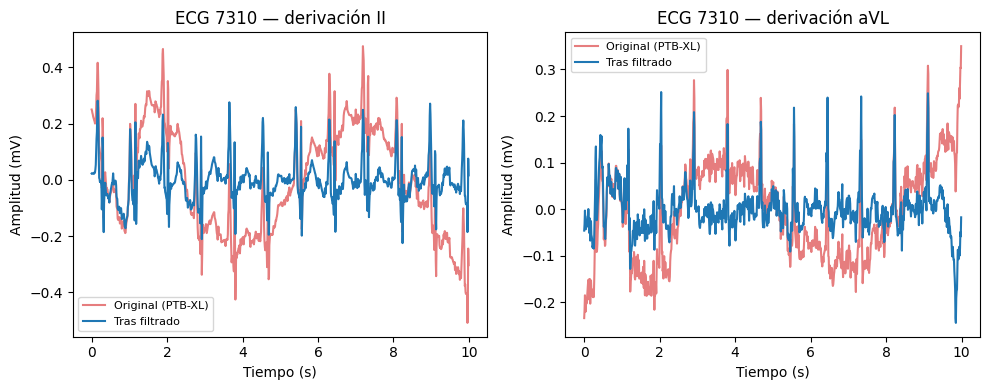

In [10]:
raw_signal, meta = wfdb.rdsamp(str(DATA_DIR / best_rel_path))
lead_names = meta["sig_name"]
print("Derivaciones disponibles:", lead_names)

clean_signal = preprocess_ecg_sin_normalizar(raw_signal)

def lead_idx(name):
    return [n.upper() for n in lead_names].index(name.upper())

t = np.arange(raw_signal.shape[0]) / FS
leads_to_plot = ["II", "aVL"]

fig, axes = plt.subplots(1, len(leads_to_plot), figsize=(10, 4))
for ax, lead in zip(axes, leads_to_plot):
    i = lead_idx(lead)
    ax.plot(t, raw_signal[:, i], color="tab:red", alpha=0.6, label="Original (PTB-XL)")
    ax.plot(t, clean_signal[:, i], color="tab:blue", label="Tras filtrado")
    ax.set_title(f"ECG {best_ecg_id} — derivación {lead}")
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Amplitud (mV)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "validacion_filtrado_2derivaciones.png", dpi=200)
plt.show()

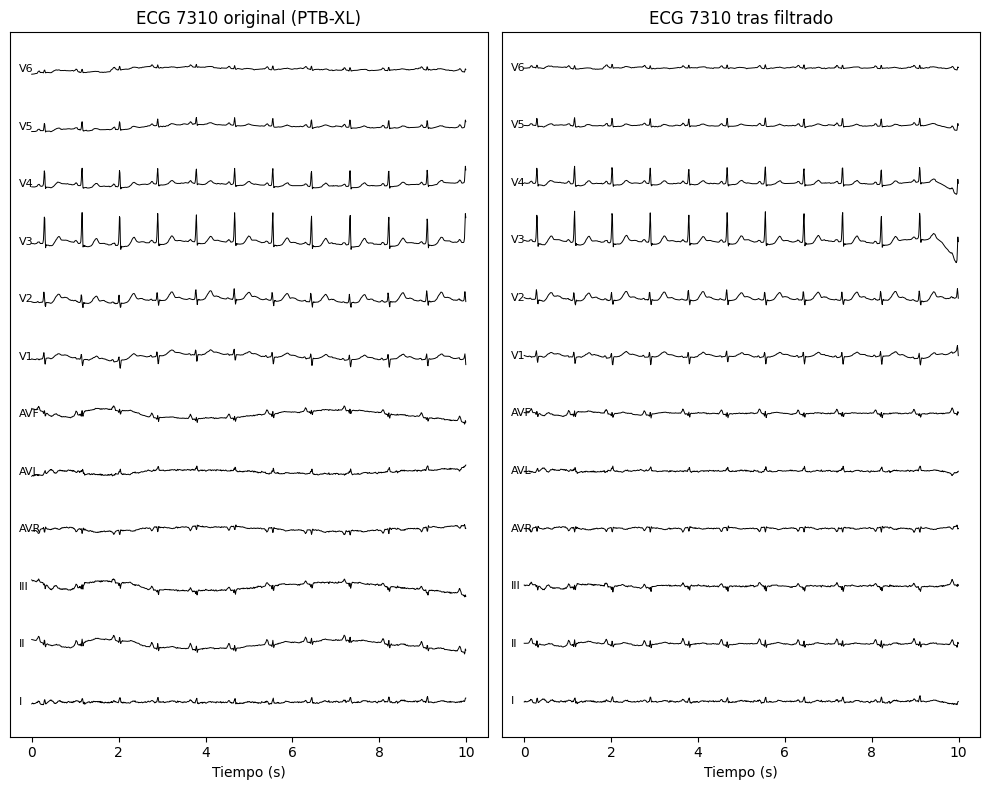

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 8))
offset = 3.0

for i, lead in enumerate(lead_names):
    axes[0].plot(t, raw_signal[:, i] + i * offset, color="black", linewidth=0.7)
    axes[0].text(-0.3, i * offset, lead, fontsize=8, va="center")
    axes[1].plot(t, clean_signal[:, i] + i * offset, color="black", linewidth=0.7)
    axes[1].text(-0.3, i * offset, lead, fontsize=8, va="center")

axes[0].set_title(f"ECG {best_ecg_id} original (PTB-XL)")
axes[1].set_title(f"ECG {best_ecg_id} tras filtrado")
for ax in axes:
    ax.set_xlabel("Tiempo (s)")
    ax.set_yticks([])

plt.tight_layout()
plt.savefig(FIG_DIR / "validacion_filtrado_12derivaciones.png", dpi=200)
plt.show()

## 6. Extracción de características: espectrograma STFT


In [7]:
def lead_to_spectrogram(lead_signal, fs=FS, nperseg=STFT_NPERSEG, noverlap=STFT_NOVERLAP, out_shape=SPEC_SHAPE):
    """Convierte una derivación 1D en su espectrograma STFT normalizado, con forma fija (F, T)."""
    _, _, Zxx = sp_signal.stft(lead_signal, fs=fs, nperseg=nperseg, noverlap=noverlap)
    mag = np.log1p(np.abs(Zxx))

    F, T = out_shape
    mag = mag[:F, :T]
    if mag.shape != (F, T):
        pad = np.zeros((F, T), dtype=np.float32)
        pad[:mag.shape[0], :mag.shape[1]] = mag
        mag = pad

    mn, mx = mag.min(), mag.max()
    if mx - mn > 1e-8:
        mag = (mag - mn) / (mx - mn)
    return mag.astype(np.float32)

def ecg_to_tensor(signal_2d):
    """signal_2d: (n_muestras, 12) -> tensor (F, T, 12)."""
    specs = [lead_to_spectrogram(signal_2d[:, i]) for i in range(signal_2d.shape[1])]
    return np.stack(specs, axis=-1)


## 7. Generación del dataset con caché en disco

A diferencia de 01, aquí **sí se llama a `preprocess_ecg`** antes de calcular el espectrograma — es la única línea que cambia respecto al notebook anterior en todo este bloque.

In [8]:
def _cache_path(rel_path):
    h = hashlib.md5(rel_path.encode()).hexdigest()
    return CACHE_DIR / f"{h}.npy"

def get_tensor_cached(rel_path):
    cp = _cache_path(rel_path)
    if cp.exists():
        return np.load(cp)
    raw, _ = wfdb.rdsamp(str(DATA_DIR / rel_path))
    clean = preprocess_ecg(raw)
    if clean is None:
        return None
    tensor = ecg_to_tensor(clean)
    np.save(cp, tensor)
    return tensor

def build_split(df_split):
    Xs, Ys = [], []
    for _, row in df_split.iterrows():
        t = get_tensor_cached(row["filename_lr"])
        if t is None:
            continue
        Xs.append(t)
        Ys.append(row["target_vec"])
    return np.stack(Xs).astype(np.float32), np.stack(Ys).astype(np.float32)

X_train, Y_train = build_split(train_df)
X_val,   Y_val   = build_split(val_df)
X_test,  Y_test  = build_split(test_df)

print("Formas:", X_train.shape, X_val.shape, X_test.shape)


Formas: (17084, 33, 64, 12) (2146, 33, 64, 12) (2158, 33, 64, 12)


## 8. Arquitectura: CNN mínima

Un único bloque convolucional (32 filtros) seguido directamente de la clasificación. Nada de regularización L2, dropout mínimo solo para evitar un colapso total. Es deliberadamente pequeña: el objetivo de este notebook es el suelo de la comparación, no un buen modelo.

In [9]:
def build_model_simple(input_shape, n_classes):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(n_classes, activation="sigmoid")(x)
    return models.Model(inputs, outputs)

model = build_model_simple(X_train.shape[1:], len(SUPER_CLASSES))
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc", multi_label=True)])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 33, 64, 12)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 33, 64, 32)          │           3,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 32)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,653 (14.27 KB)

 Trainable params: 3,653 (14.27 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Entrenamiento

Sin `pos_weight` ni focal loss: `binary_crossentropy` simple, umbral de decisión fijo en 0.5.

In [10]:
cbs = [
    callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=4, min_lr=1e-6),
    callbacks.ModelCheckpoint(str(MODEL_DIR / f"{NOTEBOOK_NAME}.keras"), monitor="val_auc",
                               mode="max", save_best_only=True),
]

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=60,
    batch_size=32,
    callbacks=cbs,
    verbose=1,
)


Epoch 1/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - auc: 0.5458 - loss: 0.5492 - val_auc: 0.6073 - val_loss: 0.5362 - learning_rate: 0.0010
Epoch 2/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/step - auc: 0.5902 - loss: 0.5359 - val_auc: 0.6337 - val_loss: 0.5296 - learning_rate: 0.0010
Epoch 3/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 15s 28ms/step - auc: 0.6188 - loss: 0.5283 - val_auc: 0.6560 - val_loss: 0.5219 - learning_rate: 0.0010
Epoch 4/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - auc: 0.6428 - loss: 0.5204 - val_auc: 0.6789 - val_loss: 0.5133 - learning_rate: 0.0010
Epoch 5/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - auc: 0.6616 - loss: 0.5134 - val_auc: 0.6979 - val_loss: 0.5053 - learning_rate: 0.0010
Epoch 6/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 42ms/step - auc: 0.6836 - loss: 0.5051 - val_auc: 0.7195 - val_loss: 0.4958 - learning_rate: 0.0010
Epoch 7/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 24s 45ms/step - auc: 0.7001 - loss: 0.4977 - val_auc: 0.7330 - val_loss: 0.4875 - learning_rate:

## 10. Evaluación sobre el conjunto de test

In [12]:
def compute_metrics(Y_true, Y_pred, Y_prob):
    """Accuracy, Precision, Recall, F1 y MAE por clase, más la fila Macro (media simple)."""
    rows = []
    for i, c in enumerate(SUPER_CLASSES):
        yt, yp, ypr = Y_true[:, i], Y_pred[:, i], Y_prob[:, i]
        tp = np.sum((yt == 1) & (yp == 1))
        tn = np.sum((yt == 0) & (yp == 0))
        fp = np.sum((yt == 0) & (yp == 1))
        fn = np.sum((yt == 1) & (yp == 0))
        acc  = (tp + tn) / len(yt)
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
        mae  = np.mean(np.abs(ypr - yt))
        rows.append([CLASS_MAP_HUMAN[c], acc, prec, rec, f1, mae])

    metrics_df = pd.DataFrame(rows, columns=["Clase", "Accuracy", "Precision", "Recall", "F1", "MAE"])
    macro = metrics_df[["Accuracy", "Precision", "Recall", "F1", "MAE"]].mean()
    metrics_df.loc[len(metrics_df)] = ["Macro"] + macro.tolist()
    return metrics_df

test_probs = model.predict(X_test, verbose=0)
test_pred  = (test_probs >= 0.5).astype(int)

metrics_df = compute_metrics(Y_test, test_pred, test_probs)
metrics_df


,Clase,Accuracy,Precision,Recall,F1,MAE
0,Normal,0.825765,0.780861,0.847352,0.812749,0.252995
1,Infarto,0.781279,0.662500,0.289091,0.402532,0.284344
2,Isquemia/ST-T,0.830399,0.762712,0.431862,0.551471,0.229623
3,Hipertrofia,0.879518,0.666667,0.015267,0.029851,0.180299
4,Conducción (bloqueos),0.830399,0.792793,0.354839,0.490251,0.258280
5,Macro,0.829472,0.733107,0.387682,0.457371,0.241108


## 11. Registro en la tabla comparativa común


In [13]:
macro_row = metrics_df[metrics_df["Clase"] == "Macro"].drop(columns="Clase").iloc[0]
result_row = pd.DataFrame([{
    "Notebook": NOTEBOOK_NAME,
    "Preprocesado": PREP_VERSION,
    "Parametros_entrenables": model.count_params(),
    **macro_row.to_dict(),
}])

if COMPARISON_CSV.exists():
    comparison = pd.read_csv(COMPARISON_CSV)
    comparison = comparison[comparison["Notebook"] != NOTEBOOK_NAME]
    comparison = pd.concat([comparison, result_row], ignore_index=True)
else:
    comparison = result_row

comparison.to_csv(COMPARISON_CSV, index=False)
comparison


,Notebook,Preprocesado,Parametros_entrenables,Accuracy,Precision,Recall,F1,MAE
0,03_cnn_profunda_con_filtrado,con_filtrado,105317,0.854310,0.733758,0.591347,0.630620,0.178831
1,04_cnn_profunda_balanceo,con_filtrado,105317,0.810936,0.577661,0.792424,0.656731,0.286431
2,05_cnn_profunda_balanceo_umbral,con_filtrado,105317,0.840871,0.637769,0.722755,0.672034,0.322418
3,01_cnn_simple_sin_filtrado,sin_filtrado,3653,0.823077,0.760360,0.346851,0.413249,0.254433
4,02_cnn_simple_con_filtrado,con_filtrado,3653,0.829472,0.733107,0.387682,0.457371,0.241108


In [14]:
PER_CLASS_CSV = MODEL_DIR / "per_class_comparison.csv"

per_class_rows = metrics_df.copy()
per_class_rows.insert(0, "Notebook", NOTEBOOK_NAME)

if PER_CLASS_CSV.exists():
    per_class_all = pd.read_csv(PER_CLASS_CSV)
    per_class_all = per_class_all[per_class_all["Notebook"] != NOTEBOOK_NAME]
    per_class_all = pd.concat([per_class_all, per_class_rows], ignore_index=True)
else:
    per_class_all = per_class_rows

per_class_all.to_csv(PER_CLASS_CSV, index=False)
per_class_rows

,Notebook,Clase,Accuracy,Precision,Recall,F1,MAE
0,02_cnn_simple_con_filtrado,Normal,0.825765,0.780861,0.847352,0.812749,0.252995
1,02_cnn_simple_con_filtrado,Infarto,0.781279,0.662500,0.289091,0.402532,0.284344
2,02_cnn_simple_con_filtrado,Isquemia/ST-T,0.830399,0.762712,0.431862,0.551471,0.229623
3,02_cnn_simple_con_filtrado,Hipertrofia,0.879518,0.666667,0.015267,0.029851,0.180299
4,02_cnn_simple_con_filtrado,Conducción (bloqueos),0.830399,0.792793,0.354839,0.490251,0.258280
5,02_cnn_simple_con_filtrado,Macro,0.829472,0.733107,0.387682,0.457371,0.241108
